# Field development: the concept screen

An illustrative gas-condensate discovery is developed against three concepts: a subsea
tieback to a host 30 km away, a normally-unmanned platform with one separator, and a manned
platform with a multi-stage separation train. The drilling report fixes the reservoir, the
fluid and the well test; the host fixes the capacity; the trunk and the onshore plant fix the
route.

The owner's rule is the screen: **one separation stage is a NUI candidate; two or more stages
require a manned platform**. The study therefore has to answer a physical question before it
can answer the commercial one - how many separation stages the fluid needs to meet the liquid
export specification.

The field, the well test and the prices are illustrative. No number here should be read as a
real field. Notebook 07 takes the shortlist and costs it.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import azoth
import azoth.eos
import azoth.process
import azoth.pvt
from azoth.core.errors import InvalidInputError, OutOfRangeError, SolverNotConvergedError

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity
R = 8.314462618
T_SC, P_SC = 288.15, 101325.0
MMSCFD_PER_MOL_S = R * T_SC / P_SC * 86400.0 / 28316.846592
BPD_PER_M3 = 1.0 / 0.158987294928


def norm(z):
    total = float(sum(z))
    return [float(value) / total for value in z]


def mix_streams(n1, z1, n2, z2):
    if n1 <= 0.0:
        return float(n2), list(z2)
    if n2 <= 0.0:
        return float(n1), list(z1)
    total = n1 + n2
    return total, [(n1 * a + n2 * b) / total for a, b in zip(z1, z2, strict=True)]


print("azoth", azoth.__version__, "| backends", sorted(azoth.backends()))

azoth 0.1.4 | backends ['python', 'rust']


## 1. The drilling report

The exploration well found a rich gas-condensate at 3,100 m TVD in 350 m of water. The
report gives the reservoir pressure and temperature, a twelve-component sample, and a
72-hour test: 2,000 mol/s of wellstream at a flowing bottomhole pressure of 150 bara, with a
backpressure exponent of 0.8. The wellhead is 95 bara at 90 °C.

The host 30 km away has 50 MMscfd of gas capacity and 30,000 bbl/d of liquids, and takes the
fluid at 45 bara. The trunk tie-in is 15 km away; the onshore plant is 150 km away.

In [2]:
COMPONENTS = [
    "methane",
    "ethane",
    "propane",
    "i-butane",
    "n-butane",
    "i-pentane",
    "n-pentane",
    "n-hexane",
    "n-heptane",
    "n-octane",
    "co2",
    "nitrogen",
]
Z_FEED = [0.70, 0.08, 0.06, 0.015, 0.03, 0.015, 0.02, 0.02, 0.02, 0.015, 0.02, 0.005]
MIXTURE, IDEAL = azoth.eos.components.mixture_of(COMPONENTS)
MOLAR_MASS = [component.molar_mass.to("kg/mol").magnitude for component in MIXTURE.components]

P_RES, T_RES = 320.0, 383.15
TVD, WATER_DEPTH = 3100.0, 350.0
P_WH, T_WH = 95.0, 363.15
P_FIRST = 60.0
WELLSTREAM = 2000.0
TEST_PWF = 150.0
IPR_N = 0.8
HOST_GAS, HOST_LIQ, HOST_P = 50.0, 30_000.0, 45.0
TIEBACK_KM, TRUNK_KM, ONSHORE_KM = 30.0, 15.0, 150.0
P_EXPORT, P_LIQ = 90.0, 20.0
T_VC = 310.93
LIQ_SPEC = 5.0
T_COOL = 313.15

basis = pd.DataFrame(
    [
        ("reservoir pressure", f"{P_RES:.0f} bara"),
        ("reservoir temperature", f"{T_RES - 273.15:.0f} degC"),
        ("true vertical depth", f"{TVD:.0f} m"),
        ("water depth", f"{WATER_DEPTH:.0f} m"),
        ("well test", f"{WELLSTREAM:.0f} mol/s at {TEST_PWF:.0f} bara bottomhole"),
        ("wellhead", f"{P_WH:.0f} bara, {T_WH - 273.15:.0f} degC"),
        ("host spare", f"{HOST_GAS:.0f} MMscfd gas, {HOST_LIQ:,.0f} bbl/d liquid"),
        ("host reception", f"{HOST_P:.0f} bara"),
        ("tieback / trunk / onshore", f"{TIEBACK_KM:.0f} / {TRUNK_KM:.0f} / {ONSHORE_KM:.0f} km"),
        ("liquid spec", f"bubble pressure at {T_VC - 273.15:.1f} degC <= {LIQ_SPEC:.0f} bara"),
    ],
    columns=["item", "value"],
)
basis

,item,value
0,reservoir pressure,320 bara
1,reservoir temperature,110 degC
2,true vertical depth,3100 m
3,water depth,350 m
4,well test,2000 mol/s at 150 bara bottomhole
5,wellhead,"95 bara, 90 degC"
6,host spare,"50 MMscfd gas, 30,000 bbl/d liquid"
7,host reception,45 bara
8,tieback / trunk / onshore,30 / 15 / 150 km
9,liquid spec,bubble pressure at 37.8 degC <= 5 bara


## 2. What the fluid does

A concept study does not need the whole phase envelope; it needs to know which phases meet
where. The map below is a PT flash grid rather than a traced envelope: on a twelve-component
fluid the continuation can fail near the critical point, while a flash grid is robust and
shows exactly the states the process uses.

The wellhead at 95 bara and 90 °C is two-phase. The choke to 60 bara is isenthalpic, so its
outlet temperature follows from the phase-weighted wellhead enthalpy rather than being
assumed; the first separator holds that temperature.

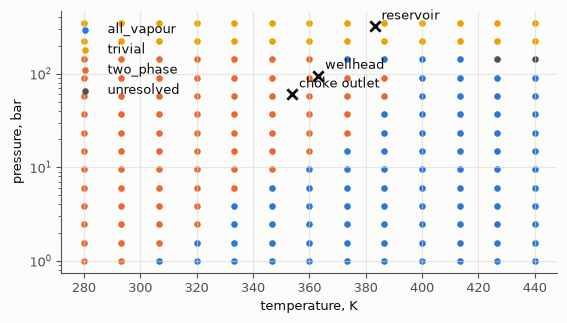

,state,T (K),P (bar),phase,vapour fraction
0,reservoir,383.1,320.0,trivial,NaN
1,wellhead,363.1,95.0,two_phase,0.912036
2,choke outlet,353.9,60.0,two_phase,0.911421


In [3]:
def phase_at(temperature, pressure):
    return azoth.eos.pt_flash(MIXTURE, q(temperature, "K"), q(pressure, "bar"), Z_FEED)


wellhead = phase_at(T_WH, P_WH)
beta_wh = wellhead.vapour_fraction
h_vapour = (
    azoth.eos.molar_enthalpy_entropy(
        MIXTURE, IDEAL, q(T_WH, "K"), q(P_WH, "bar"), list(wellhead.y), wellhead.z_vapour
    )
    .h.to("J/mol")
    .magnitude
)
h_liquid = (
    azoth.eos.molar_enthalpy_entropy(
        MIXTURE, IDEAL, q(T_WH, "K"), q(P_WH, "bar"), list(wellhead.x), wellhead.z_liquid
    )
    .h.to("J/mol")
    .magnitude
)
h_wellhead = beta_wh * h_vapour + (1.0 - beta_wh) * h_liquid
choke = azoth.eos.ph_flash(MIXTURE, IDEAL, q(P_FIRST, "bar"), q(h_wellhead, "J/mol"), Z_FEED)
T_FIRST = choke.T

temperatures = np.linspace(280.0, 440.0, 13)
pressures = np.geomspace(1.0, 350.0, 14)
points = []
for temperature in temperatures:
    for pressure in pressures:
        try:
            state = phase_at(float(temperature), float(pressure))
            points.append((float(temperature), float(pressure), state.phase.value))
        except (SolverNotConvergedError, OutOfRangeError, InvalidInputError):
            points.append((float(temperature), float(pressure), "unresolved"))
map_points = pd.DataFrame(points, columns=["T", "P", "phase"])

fig, ax = plt.subplots()
colours = {
    "all_vapour": PALETTE[0],
    "two_phase": PALETTE[1],
    "all_liquid": PALETTE[2],
    "trivial": PALETTE[3],
    "unresolved": MUTED,
}
for phase, group in map_points.groupby("phase"):
    ax.scatter(group["T"], group["P"], s=14, color=colours.get(phase, MUTED), label=phase)
states = {
    "reservoir": (T_RES, P_RES),
    "wellhead": (T_WH, P_WH),
    "choke outlet": (T_FIRST.to("K").magnitude, P_FIRST),
}
for label, (temperature, pressure) in states.items():
    ax.scatter([temperature], [pressure], marker="x", s=55, color=INK, zorder=5)
    ax.annotate(
        label, (temperature, pressure), textcoords="offset points", xytext=(5, 5), color=INK
    )
ax.set_yscale("log")
ax.set_xlabel("temperature, K")
ax.set_ylabel("pressure, bar")
ax.legend(frameon=False, loc="upper left")
plt.show()
plt.close(fig)

rows = []
for label, temperature, pressure, state in (
    ("reservoir", T_RES, P_RES, phase_at(T_RES, P_RES)),
    ("wellhead", T_WH, P_WH, wellhead),
    ("choke outlet", T_FIRST.to("K").magnitude, P_FIRST, choke),
):
    rows.append(
        {
            "state": label,
            "T (K)": round(temperature, 1),
            "P (bar)": pressure,
            "phase": state.phase.value,
            "vapour fraction": state.vapour_fraction,
        }
    )
pd.DataFrame(rows)

## 3. What the well can deliver

The test fixes a backpressure relation, `q = C (P_res^2 - P_wf^2)^n`. It sets what the well
can do at a drawdown; the plateau is a facility choice, not a reservoir limit. After the
plateau the production forecast is an Arps hyperbolic decline at 10 %/year with `b = 0.8`.

The host's 50 MMscfd spare is drawn on the production plot in sales-gas terms, using a 0.95
gas yield as a placeholder; the separation study below computes the real yield.

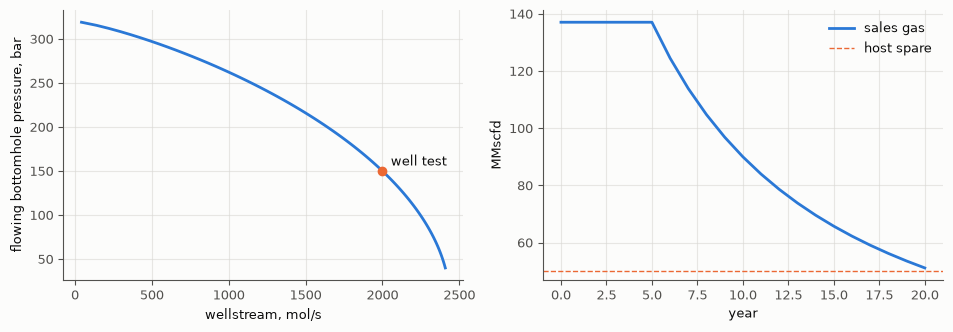

In [4]:
C_BP = WELLSTREAM / (P_RES**2 - TEST_PWF**2) ** IPR_N
pwf = np.linspace(40.0, P_RES - 1.0, 80)
ipr = C_BP * np.maximum(P_RES**2 - pwf**2, 0.0) ** IPR_N

PLATEAU_YEARS = 5.0
DECLINE = 0.10
forecast = azoth.pvt.decline_curve(
    "forecast",
    qi=WELLSTREAM,
    di=DECLINE / 365.25,
    b=0.8,
    t_start=0.0,
    t_end=(20.0 - PLATEAU_YEARS) * 365.25,
    t_step=365.25,
)
years = np.concatenate(
    [
        np.arange(0.0, PLATEAU_YEARS + 1.0),
        PLATEAU_YEARS + np.array(forecast.time[1:]) / 365.25,
    ]
)
rates = np.concatenate([np.full(int(PLATEAU_YEARS) + 1, WELLSTREAM), np.array(forecast.rate[1:])])
GAS_YIELD_PLACEHOLDER = 0.95

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.4))
left.plot(ipr, pwf, color=PALETTE[0])
left.scatter([WELLSTREAM], [TEST_PWF], color=PALETTE[1], zorder=5)
left.annotate("well test", (WELLSTREAM, TEST_PWF), textcoords="offset points", xytext=(6, 4))
left.set_xlabel("wellstream, mol/s")
left.set_ylabel("flowing bottomhole pressure, bar")

right.plot(
    years,
    rates * GAS_YIELD_PLACEHOLDER * MMSCFD_PER_MOL_S,
    color=PALETTE[0],
    label="sales gas",
)
right.axhline(HOST_GAS, color=PALETTE[1], linestyle="--", linewidth=1.0, label="host spare")
right.set_xlabel("year")
right.set_ylabel("MMscfd")
right.legend(frameon=False)
plt.tight_layout()
plt.show()
plt.close(fig)

## 4. How many separation stages

The first-stage separator receives the wellstream at 95 bara and holds the choke outlet
temperature at 60 bara. Each lower stage is an isenthalpic let-down followed by a separator,
and the liquid cascades downward. The screen is the final liquid's vapour pressure at
37.8 °C, which must not exceed 5 bara for the export line and its custody transfer.

Compression is modelled as an isentropic chain with intercooling to 40 °C and a maximum
pressure ratio of 2.5 per stage. The interstage condensate a real cooler would drop out is
not modelled separately; it is named in notebook 07's limitations. The stock-tank liquid is the final
separator liquid flashed at 1 atm and 15 °C.

In [5]:
def boost_gas(n_mol_s, z, p_in, p_out, eta=0.78, t_cool=T_COOL, ratio_max=2.5):
    stages = max(1, math.ceil(math.log(p_out / p_in) / math.log(ratio_max)))
    ratio = (p_out / p_in) ** (1.0 / stages)
    power = duty = 0.0
    n, z = float(n_mol_s), norm(z)
    p, t = p_in, t_cool
    for _ in range(stages):
        compressed = azoth.process.compressor(
            COMPONENTS,
            q(n, "mol/s"),
            z,
            q(p, "bar"),
            q(t, "K"),
            eta,
            outlet_pressure=q(p * ratio, "bar"),
        )
        power += compressed.power.to("kW").magnitude
        cooled = azoth.process.cooler(
            COMPONENTS,
            compressed.outlet_n,
            list(compressed.outlet_z),
            compressed.outlet_p,
            compressed.outlet_t,
            outlet_temperature=q(t_cool, "K"),
        )
        duty += abs(cooled.outlet_duty.to("kW").magnitude)
        n = cooled.outlet_n.to("mol/s").magnitude
        z = norm(list(cooled.outlet_z))
        p = cooled.outlet_p.to("bar").magnitude
        t = t_cool
    return {"n": n, "z": z, "power_kw": power, "duty_kw": duty, "stages": stages}


def stock_tank(n_mol_s, z):
    z = norm(z)
    flash = azoth.eos.pt_flash(MIXTURE, q(T_SC, "K"), q(P_SC, "bar"), z)
    if flash.phase.value == "all_liquid":
        beta, x = 0.0, z
    elif flash.phase.value in {"all_vapour", "trivial"}:
        beta, x = 1.0, z
    else:
        beta = max(0.0, min(1.0, flash.vapour_fraction or 0.0))
        x = list(flash.x)
    n_liq = n_mol_s * (1.0 - beta)
    n_gas = n_mol_s * beta
    if n_liq <= 0.0:
        return {"bpd": 0.0, "gas_n": n_gas, "gas_z": z}
    m_liq = sum(a * b for a, b in zip(x, MOLAR_MASS, strict=True))
    v_liq = azoth.eos.pr_molar_volume(flash.z_liquid, q(T_SC, "K"), q(P_SC, "bar")).v
    rho = azoth.eos.pr_mass_density(q(m_liq, "kg/mol"), v_liq).rho.to("kg/m**3").magnitude
    bpd = n_liq * m_liq / rho * 86400.0 * BPD_PER_M3
    return {"bpd": bpd, "gas_n": n_gas, "gas_z": z}


def run_train(later, total=WELLSTREAM, design=False):
    separator_kwargs = {
        "mechanical_design": design,
        "design_gas_load_factor": q(0.11, "m/s") if design else None,
    }
    vessel = azoth.process.separator(
        COMPONENTS,
        q(total, "mol/s"),
        Z_FEED,
        q(P_WH, "bar"),
        T_FIRST,
        q(P_WH - P_FIRST, "bar"),
        0.0,
        **separator_kwargs,
    )
    gases = [(vessel.vapour_n.to("mol/s").magnitude, list(vessel.vapour_z), P_FIRST)]
    stages = [
        {
            "stage": 1,
            "p": P_FIRST,
            "t": T_FIRST.to("K").magnitude,
            "gas": vessel.vapour_n.to("mol/s").magnitude,
            "liquid": vessel.liquid_n.to("mol/s").magnitude,
            "separator": vessel,
        }
    ]
    n, z, p, t = vessel.liquid_n, list(vessel.liquid_z), vessel.liquid_p, vessel.liquid_t
    for index, target in enumerate(later, start=2):
        valve = azoth.process.throttling_valve(
            COMPONENTS, n, z, p, t, outlet_pressure=q(target, "bar")
        )
        vessel = azoth.process.separator(
            COMPONENTS,
            valve.outlet_n,
            list(valve.outlet_z),
            valve.outlet_p,
            valve.outlet_t,
            q(0.0, "bar"),
            0.0,
            **separator_kwargs,
        )
        gases.append((vessel.vapour_n.to("mol/s").magnitude, list(vessel.vapour_z), target))
        stages.append(
            {
                "stage": index,
                "p": target,
                "t": vessel.vapour_t.to("K").magnitude,
                "gas": vessel.vapour_n.to("mol/s").magnitude,
                "liquid": vessel.liquid_n.to("mol/s").magnitude,
                "separator": vessel,
            }
        )
        n, z, p, t = vessel.liquid_n, list(vessel.liquid_z), vessel.liquid_p, vessel.liquid_t

    power = duty = 0.0
    gas_n = 0.0
    gas_z = None
    compression = []
    for gn, gz, gp in gases:
        boost = boost_gas(gn, gz, gp, P_EXPORT)
        power += boost["power_kw"]
        duty += boost["duty_kw"]
        gas_n, gas_z = mix_streams(gas_n, gas_z, boost["n"], boost["z"])
        compression.append(boost)
    n_liq, z_liq = n.to("mol/s").magnitude, list(z)
    bubble = azoth.eos.bubble_pressure(MIXTURE, q(T_VC, "K"), norm(z_liq)).pressure
    tank = stock_tank(n_liq, z_liq)
    pump_kw = pump_head = 0.0
    if p.to("bar").magnitude < P_LIQ + 5.0:
        pump = azoth.process.pump(
            COMPONENTS,
            q(n_liq, "mol/s"),
            norm(z_liq),
            p,
            t,
            0.75,
            outlet_pressure=q(P_LIQ + 5.0, "bar"),
        )
        pump_kw = pump.power.to("kW").magnitude
        pump_head = pump.head.to("m").magnitude if pump.head is not None else 0.0
    return {
        "stages": stages,
        "sales_n": gas_n + tank["gas_n"],
        "gas_z": gas_z,
        "bpd": tank["bpd"],
        "bubble": bubble.to("bar").magnitude,
        "power_kw": power,
        "duty_kw": duty,
        "n_liq": n_liq,
        "z_liq": z_liq,
        "pump_kw": pump_kw,
        "pump_head": pump_head,
        "compression": compression,
    }


CASES = {
    "N1 60": [],
    "N2 60/10": [10],
    "N2 60/2": [2],
    "N3 60/10/2": [10, 2],
}
results = {name: run_train(later) for name, later in CASES.items()}

train_table = pd.DataFrame(
    [
        {
            "train": name,
            "stages": len(result["stages"]),
            "final liquid (K)": round(result["stages"][-1]["t"], 1),
            "bubble at 37.8 degC (bara)": round(result["bubble"], 2),
            "meets spec": "yes" if result["bubble"] <= LIQ_SPEC else "no",
            "sales gas (MMscfd)": round(result["sales_n"] * MMSCFD_PER_MOL_S, 1),
            "stock tank (bbl/d)": round(result["bpd"]),
            "compression (MW)": round(result["power_kw"] / 1000.0, 2),
            "pump (kW)": round(result["pump_kw"], 1),
        }
        for name, result in results.items()
    ]
)
train_table

,train,stages,final liquid (K),bubble at 37.8 degC (bara),meets spec,sales gas (MMscfd),stock tank (bbl/d),compression (MW),pump (kW)
0,N1 60,1,353.9,48.41,no,131.5,8207,1.94,0.0
1,N2 60/10,2,338.7,7.57,no,135.8,6799,2.28,32.0
2,N2 60/2,2,316.3,1.83,yes,137.9,5634,2.75,38.4
3,N3 60/10/2,3,324.7,1.50,yes,137.2,6107,2.40,42.3


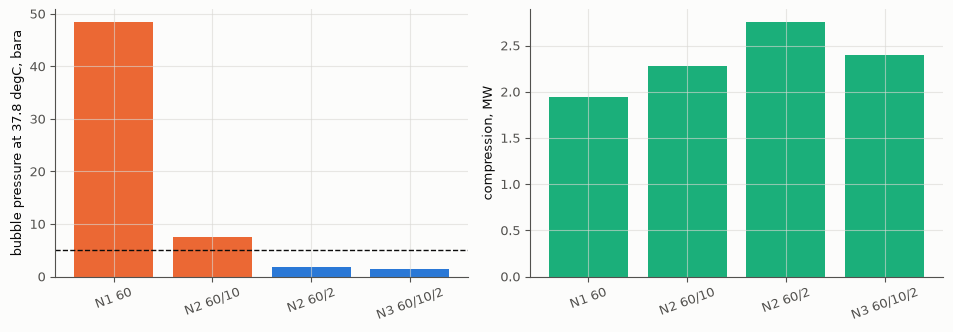

In [6]:
names = list(results)
bubbles = [results[name]["bubble"] for name in names]
power = [results[name]["power_kw"] / 1000.0 for name in names]

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.4))
left.bar(
    names,
    bubbles,
    color=[PALETTE[0] if value <= LIQ_SPEC else PALETTE[1] for value in bubbles],
)
left.axhline(LIQ_SPEC, color=INK, linestyle="--", linewidth=1.0)
left.set_ylabel("bubble pressure at 37.8 degC, bara")
left.tick_params(axis="x", rotation=20)
right.bar(names, power, color=PALETTE[2])
right.set_ylabel("compression, MW")
right.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
plt.close(fig)

The one-stage liquid is at 48 bara, far above the 5 bara limit: a NUI with a single
separator cannot ship this fluid. Two stages at 60/10 are still at 7.6 bara. The second stage
has to run near 2 bara; either a two-stage train at 60/2 or a three-stage train at 60/10/2
meets the limit.

The three-stage train carries less compression because the 10 bara gas is compressed from 10
rather than from 2, and it recovers more liquid; it is selected. Either way the platform is
manned: the owner's rule is met by the stage count, not by preference.

## 5. Can the host take it?

The selected train makes about 137 MMscfd of sales gas and 6,100 bbl/d of stock-tank
liquid. The host's spare gas capacity is 50 MMscfd, so a tieback is possible only at about
36 % of the field rate; the liquids are far inside the 30,000 bbl/d spare. The question then is
whether the 30 km multiphase line still arrives above the host's 45 bara reception at the
curtailed rate, and what the full field rate would need.

In [7]:
selected = results["N3 60/10/2"]
GAS_YIELD = selected["sales_n"] / WELLSTREAM
curtailed = HOST_GAS / MMSCFD_PER_MOL_S / GAS_YIELD

rows = []
for label, rate in (("curtailed", curtailed), ("full field", WELLSTREAM)):
    for inches, diameter in ((8, 0.2032), (10, 0.254), (12, 0.3048), (14, 0.3556)):
        try:
            line = azoth.eos.pipe_beggs_and_brills(
                COMPONENTS,
                rate,
                Z_FEED,
                q(P_WH, "bar"),
                q(T_WH, "K"),
                q(TIEBACK_KM * 1000.0, "m"),
                q(diameter, "m"),
                q(0.0, "m"),
                20,
                q(4.6e-5, "m"),
            )
            arrival = line.outlet_pressure.to("bar").magnitude
            rows.append(
                {
                    "case": label,
                    "line (in)": inches,
                    "wellstream (mol/s)": round(rate),
                    "arrival (bara)": round(arrival, 1),
                    "host reception": "met" if arrival >= HOST_P else "not met",
                }
            )
        except (InvalidInputError, OutOfRangeError):
            rows.append(
                {
                    "case": label,
                    "line (in)": inches,
                    "wellstream (mol/s)": round(rate),
                    "arrival (bara)": np.nan,
                    "host reception": "line does not deliver",
                }
            )
tieback_table = pd.DataFrame(rows)

print(
    f"gas yield {GAS_YIELD:.3f} | curtailed wellstream {curtailed:.0f} mol/s | "
    f"sales gas {selected['sales_n'] * MMSCFD_PER_MOL_S:.1f} MMscfd | "
    f"stock tank {selected['bpd']:.0f} bbl/d"
)
curtailed_bpd = selected["bpd"] * HOST_GAS / (selected["sales_n"] * MMSCFD_PER_MOL_S)
print(
    f"host spare {HOST_GAS:.0f} MMscfd gas and {HOST_LIQ:,.0f} bbl/d liquid; "
    f"liquids at the curtailed rate about {curtailed_bpd:.0f} bbl/d"
)
tieback_table

gas yield 0.951 | curtailed wellstream 729 mol/s | sales gas 137.2 MMscfd | stock tank 6107 bbl/d
host spare 50 MMscfd gas and 30,000 bbl/d liquid; liquids at the curtailed rate about 2226 bbl/d


,case,line (in),wellstream (mol/s),arrival (bara),host reception
0,curtailed,8,729,NaN,line does not deliver
1,curtailed,10,729,76.1,met
2,curtailed,12,729,89.2,met
3,curtailed,14,729,92.4,met
4,full field,8,2000,NaN,line does not deliver
5,full field,10,2000,NaN,line does not deliver
6,full field,12,2000,NaN,line does not deliver
7,full field,14,2000,68.8,met


## 6. The selected train

Sizing the selected three-stage train: each vessel is designed on the API 12J gas load
factor of 0.11 m/s, and the compression and pumping duties come from the same calls the
screen used. The gas from the two lower stages is compressed to the 90 bara export pressure;
the liquid leaves the last stage at 2 bara and is pumped to the 25 bara line pressure.

In [8]:
detail = run_train([10, 2], design=True)

rows = []
for stage in detail["stages"]:
    vessel = stage["separator"]
    rows.append(
        {
            "stage": stage["stage"],
            "pressure (bara)": stage["p"],
            "temperature (K)": round(stage["t"], 1),
            "gas (mol/s)": round(stage["gas"], 1),
            "liquid (mol/s)": round(stage["liquid"], 1),
            "D (m)": round(vessel.design_inner_diameter.to("m").magnitude, 2),
            "L (m)": round(vessel.design_tantan_length.to("m").magnitude, 2),
            "volume (m3)": round(vessel.vessel_volume.to("m**3").magnitude, 1),
            "weight (t)": round(vessel.total_weight.to("kg").magnitude / 1000.0, 1),
        }
    )
separators = pd.DataFrame(rows)
machines = pd.DataFrame(
    [
        {
            "service": f"stage {index + 1} gas to {P_EXPORT:.0f} bara",
            "stages": boost["stages"],
            "power (kW)": round(boost["power_kw"]),
            "cooling (kW)": round(boost["duty_kw"]),
        }
        for index, boost in enumerate(detail["compression"])
    ]
)
print(
    f"bubble {detail['bubble']:.2f} bara | stock tank {detail['bpd']:.0f} bbl/d | "
    f"sales gas {detail['sales_n'] * MMSCFD_PER_MOL_S:.1f} MMscfd | "
    f"pump {detail['pump_kw']:.0f} kW at {detail['pump_head']:.0f} m"
)
display(separators)
display(machines)

bubble 1.50 bara | stock tank 6107 bbl/d | sales gas 137.2 MMscfd | pump 42 kW at 489 m


,stage,pressure (bara),temperature (K),gas (mol/s),liquid (mol/s),D (m),L (m),volume (m3),weight (t)
0,1,60.0,353.9,1822.8,177.2,1.96,7.26,21.9,78.9
1,2,10.0,338.7,59.3,117.9,1.61,8.03,16.3,58.7
2,3,2.0,324.7,19.5,98.4,1.53,7.64,14.0,50.6


,service,stages,power (kW),cooling (kW)
0,stage 1 gas to 90 bara,1,1942,3478
1,stage 2 gas to 90 bara,3,337,687
2,stage 3 gas to 90 bara,5,121,420


## 7. The screening conclusion

Three gates decide the concept, in order: the host's gas capacity, the liquid's vapour
pressure (and so the separation-stage count), and the hydraulics of the route. The NUI is
screened out on the second gate; the tieback passes the hydraulic gate only at the curtailed
36 % of the field rate. Notebook 07 takes the tieback-curtailed case and the manned platform with its two
export routes, costs them and recommends.

In [9]:
concept_table = pd.DataFrame(
    [
        {
            "concept": "subsea tieback",
            "gate": "host gas capacity",
            "answer": (
                f"{HOST_GAS:.0f} of {selected['sales_n'] * MMSCFD_PER_MOL_S:.0f} MMscfd; "
                "10-inch 30 km line delivers above 45 bara at the curtailed rate; "
                "14-inch at the full field rate"
            ),
            "outcome": "shortlisted",
        },
        {
            "concept": "NUI, one separator",
            "gate": "liquid vapour pressure",
            "answer": (
                f"{results['N1 60']['bubble']:.1f} bara against a {LIQ_SPEC:.0f} bara limit"
            ),
            "outcome": "not compliant",
        },
        {
            "concept": "manned, three stages",
            "gate": "liquid vapour pressure",
            "answer": (
                f"{results['N3 60/10/2']['bubble']:.1f} bara against a {LIQ_SPEC:.0f} bara limit"
            ),
            "outcome": "shortlisted",
        },
    ]
)
display(concept_table)
print(
    "handover to notebook 07: three-stage train at 60/10/2 bara; "
    f"{selected['sales_n'] * MMSCFD_PER_MOL_S:.1f} MMscfd gas at {P_EXPORT:.0f} bara; "
    f"{selected['bpd']:.0f} bbl/d stabilised liquid; "
    f"{selected['power_kw'] / 1000.0:.2f} MW compression and {selected['pump_kw']:.0f} kW pumping"
)

,concept,gate,answer,outcome
0,subsea tieback,host gas capacity,50 of 137 MMscfd; 10-inch 30 km line delivers ...,shortlisted
1,"NUI, one separator",liquid vapour pressure,48.4 bara against a 5 bara limit,not compliant
2,"manned, three stages",liquid vapour pressure,1.5 bara against a 5 bara limit,shortlisted


handover to notebook 07: three-stage train at 60/10/2 bara; 137.2 MMscfd gas at 90 bara; 6107 bbl/d stabilised liquid; 2.40 MW compression and 42 kW pumping
